# Restauración de fotografías antiguas con CycleGAN
**Tercer Mini Proyecto — Redes Neuronales y Deep Learning (UAO)**

Traducción imagen a imagen **no pareada**: dominio **A** = fotografías antiguas (blanco y negro o sepia), dominio **B** = fotografías modernas a color. El dataset lo construimos nosotros descargando las imágenes una por una.

Estructura: 1. Entorno · 2. Datos · 3. Hiperparámetros · 4. Modelo · 5. Entrenamiento · 6. Evaluación · 7. Comparación · 8. Prueba con datos propios.

**Trazabilidad.** Cada celda de código empieza con `# Fuente:`, que indica el cuaderno del curso y la celda de donde sale cada función. Las celdas se cuentan solo entre las celdas de código, empezando en 1. Lo que no aparece en ningún cuaderno del curso va marcado con `# EXCEPCIÓN` y un código:

| Código | Qué cubre |
|---|---|
| E1 | `tf.image.psnr` y `tf.image.ssim` sobre degradación sintética |
| E3 | KID con InceptionV3 preentrenada (precedente: VGG16 de `keras.applications` en DETECTOR_DE_OBJETOS) |
| E4 | `google.colab.files.upload()` |
| E7 | Relleno por reflexión con `tf.pad` |
| E8 | `hashlib` para detectar duplicados |
| F1 | Lectura y aumentación de imágenes con `tf.image` dentro de `tf.data` |
| F2 | Normalización por instancia (`add_weight`, `tf.nn.moments`, `tf.sqrt`) |
| F3 | Conexión residual con `layers.Add` |
| F4 | Inicializador `RandomNormal(stddev=0.02)` |
| F5 | Pérdidas del bucle propio: `BinaryCrossentropy`, `ones_like`, `zeros_like`, `tf.abs`, `GradientTape(persistent=True)` |
| F6 | `tf.train.Checkpoint` y `CheckpointManager` |
| F7 | `save_weights` |
| F8 | `tf.data.Dataset.zip` |
| F9 | `tf.keras.utils.set_random_seed` |
| F10 | Utilidades menores: `shutil`, `os.path.exists`, escritura de CSV y métodos de pandas, `stratify`, `np.std`, `np.abs`, `layers.ReLU` como capa |
| S1 | `zipfile` y `Path.rglob`/`relative_to` (alternativa del curso: `!unzip` y `glob`) |
| S2 | Degradación sintética con `tf.image`/`tf.nn` (alternativa del curso: `cv2` de Semana_8) |
| S3 | `np.random.default_rng` y `np.trace` en el KID |

La arquitectura CycleGAN (generador ResNet, discriminador PatchGAN, pérdidas de ciclo e identidad) sigue el tutorial CycleGAN de TensorFlow y el repositorio de junyanz, ambos enlazados en el enunciado del miniproyecto.

## 1. Entorno

In [ ]:
# Celda 1 — Entorno, versiones y semillas
# Fuente: Copia_de_Gan_RED.ipynb, celda 1 (verificación de GPU con tf.test.gpu_device_name);
#         Copia_de_GAN_mnist.ipynb, celda 1 (impresión de tf.__version__)
# EXCEPCIÓN F9: tf.keras.utils.set_random_seed. El curso fija np.random.seed y random.seed
#         (Copie_de_Semana_2.ipynb, celda 21), pero eso no fija la semilla de TensorFlow.
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
    print("AVISO: no se encontró GPU. Entrenar en CPU es inviable; activar GPU en Entorno de ejecución.")
else:
    print('GPU encontrada en: {}'.format(device_name))

# Reproducibilidad: fija las semillas de Python, NumPy y TensorFlow.
# En GPU algunas operaciones no son deterministas, así que dos corridas pueden diferir levemente.
SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)

TensorFlow: 2.21.0 | Keras: 3.13.2
AVISO: no se encontró GPU. Entrenar en CPU es inviable; activar GPU en Entorno de ejecución.


In [ ]:
# Celda 2 — Drive, rutas y bandera de entrenamiento
# Fuente: Copia_de_Gan_RED.ipynb, celda 2 (drive.mount); Copia_de_Detectron2_Tutorial.ipynb, celda 11 (os.makedirs)
# EXCEPCIÓN F10: os.path.exists para avisar si faltan los zip en Drive.
from google.colab import drive
drive.mount('/content/drive')

# True: entrena desde cero o continúa desde el último checkpoint.
# False: no entrena, carga los pesos guardados (usar en la sustentación).
ENTRENAR = False

ROOT  = "/content/drive/MyDrive/CycleGAN"
ZIP_A = f"{ROOT}/trainA.zip"   # fotos antiguas
ZIP_B = f"{ROOT}/trainB.zip"   # fotos modernas

DATASET_ROOT = "/content/dataset"
TRAIN_A = f"{DATASET_ROOT}/trainA"
TRAIN_B = f"{DATASET_ROOT}/trainB"

# v1 = primer entrenamiento (carpetas sin sufijo, se conservan como punto de comparación).
# v2 = este entrenamiento: pérdida supervisada con envejecimiento sintético, tasa con decaimiento e interpolación bilineal.
VERSION = "v2"
CKPT_DIR    = f"{ROOT}/checkpoints_restore_{VERSION}"
MODELOS_DIR = f"{ROOT}/models_restore_{VERSION}"
RESULT_DIR  = f"{ROOT}/resultados_{VERSION}"
for d in [CKPT_DIR, MODELOS_DIR, RESULT_DIR, f"{RESULT_DIR}/progreso", f"{RESULT_DIR}/propias", f"{ROOT}/resultados"]:
    os.makedirs(d, exist_ok=True)

PESOS = {
    "final_A2B": f"{MODELOS_DIR}/G_A2B_final.weights.h5",
    "final_B2A": f"{MODELOS_DIR}/G_B2A_final.weights.h5",
    "mitad_A2B": f"{MODELOS_DIR}/G_A2B_mitad.weights.h5",
    "mitad_B2A": f"{MODELOS_DIR}/G_B2A_mitad.weights.h5",
}
HISTORIAL_CSV = f"{RESULT_DIR}/historial_perdidas.csv"
PARTICION_CSV = f"{ROOT}/resultados/particion.csv"   # la misma partición del primer entrenamiento
PESOS_V1 = {"A2B": f"{ROOT}/models_restore/G_A2B_final.weights.h5",   # generadores del primer entrenamiento
            "B2A": f"{ROOT}/models_restore/G_B2A_final.weights.h5"}

for z in [ZIP_A, ZIP_B]:
    if not os.path.exists(z):
        raise FileNotFoundError(f"No se encontró {z}. Suban trainA.zip y trainB.zip a {ROOT}")
print("Rutas listas. ENTRENAR =", ENTRENAR)

Mounted at /content/drive
Rutas listas. ENTRENAR = False


## 2. Datos

In [ ]:
# Celda 3 — Descompresión y listado de imágenes
# Fuente: Copia_de_Detectron2_Tutorial.ipynb, celda 8 (descompresión con !unzip);
#         Copia_de_DETECTOR_DE_OBJETOS.ipynb, celda 7 (glob y pathlib)
# EXCEPCIÓN S1: zipfile y Path.rglob en lugar de !unzip y glob (mismo resultado; rglob además
#         entra a subcarpetas, acepta .JPG en mayúscula e ignora __MACOSX).
# EXCEPCIÓN F10: shutil.rmtree para borrar la extracción anterior.
import zipfile, shutil
from pathlib import Path

EXTENSIONES = {".jpg", ".jpeg", ".png"}

def unzip_to(zip_path, dest_path):
    print(f"Descomprimiendo {zip_path} en {dest_path}...")
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(dest_path)

def listar_imagenes(base_dir):
    # Recorre subcarpetas (el zip puede traer trainA/ adentro), acepta .JPG en mayúscula
    # e ignora la basura que agregan macOS (__MACOSX) y los archivos ocultos.
    archivos = []
    for p in Path(base_dir).rglob("*"):
        if not p.is_file() or "__MACOSX" in p.parts or p.name.startswith("."):
            continue
        if p.suffix.lower() in EXTENSIONES:
            archivos.append(str(p))
    return sorted(archivos)   # orden fijo para que la partición sea reproducible

# Se borra la extracción anterior para que no queden imágenes viejas si el zip cambió
shutil.rmtree(DATASET_ROOT, ignore_errors=True)
unzip_to(ZIP_A, TRAIN_A)
unzip_to(ZIP_B, TRAIN_B)

archivos_A = listar_imagenes(TRAIN_A)
archivos_B = listar_imagenes(TRAIN_B)
print("Imágenes encontradas | A (antiguas):", len(archivos_A), "| B (modernas):", len(archivos_B))

Descomprimiendo /content/drive/MyDrive/CycleGAN/trainA.zip en /content/dataset/trainA...
Descomprimiendo /content/drive/MyDrive/CycleGAN/trainB.zip en /content/dataset/trainB...
Imágenes encontradas | A (antiguas): 150 | B (modernas): 150


In [ ]:
# Celda 4 — Limpieza: archivos corruptos, imágenes pequeñas y duplicados
# Fuente: Copia_de_Detectron2_Tutorial.ipynb, celda 9 (open() para leer archivos)
# EXCEPCIÓN E8: hashlib (librería estándar) detecta duplicados exactos; un duplicado repartido
#         entre entrenamiento y prueba sería una fuga de datos.
# EXCEPCIÓN F1: tf.image.decode_image para detectar archivos corruptos y medir su tamaño.
import hashlib

MIN_LADO = 256   # lado menor mínimo; ampliar fotos más pequeñas mete desenfoque en el dominio

def limpiar(archivos, dominio, vistos):
    validos, corruptos, pequenas, duplicados = [], [], [], []
    for p in archivos:
        datos = open(p, "rb").read()
        h = hashlib.md5(datos).hexdigest()
        if h in vistos:
            duplicados.append((Path(p).name, Path(vistos[h]).name))
            continue
        try:
            img = tf.image.decode_image(datos, channels=3, expand_animations=False)
        except Exception:
            corruptos.append(Path(p).name)
            continue
        if min(img.shape[0], img.shape[1]) < MIN_LADO:
            pequenas.append(Path(p).name)
            continue
        vistos[h] = p
        validos.append(p)
    print(f"Dominio {dominio}: válidas={len(validos)} | corruptas={len(corruptos)} | "
          f"pequeñas (<{MIN_LADO}px)={len(pequenas)} | duplicadas={len(duplicados)}")
    for nombre, original in duplicados:
        print(f"   duplicada: {nombre} = {original}")
    if corruptos: print("   corruptas:", corruptos)
    if pequenas:  print("   pequeñas:", pequenas)
    return validos

vistos = {}   # compartido: también detecta la misma foto puesta en A y en B
archivos_A = limpiar(archivos_A, "A", vistos)
archivos_B = limpiar(archivos_B, "B", vistos)

if min(len(archivos_A), len(archivos_B)) < 10:
    raise ValueError("Quedan muy pocas imágenes válidas para entrenar y evaluar.")

Dominio A: válidas=150 | corruptas=0 | pequeñas (<256px)=0 | duplicadas=0
Dominio B: válidas=150 | corruptas=0 | pequeñas (<256px)=0 | duplicadas=0


In [ ]:
# Celda 5 — Partición entrenamiento / prueba (80/20) sin fugas
# Fuente: Copia_de_Semana_5_Regresion_y_clasificacion.ipynb, celda 20 (train_test_split con random_state);
#         Copie_de_Semana_3_Concrete_Compressive_Strength_RNA_1_1.ipynb, celda 3 (pandas DataFrame);
#         Copia_de_Autoendores_function.ipynb, celda 3 (pd.read_csv); Copia_de_DETECTOR_DE_OBJETOS.ipynb, celda 28 (Path)
# EXCEPCIÓN F10: parámetro stratify, to_csv, sort_values, equals y os.path.exists.
# EXCEPCIÓN S1: Path.relative_to.
from sklearn.model_selection import train_test_split

def categoria(p):
    return Path(p).name.split("_")[0]   # retrato_A_001.jpg -> retrato

def partir(archivos):
    # Estratificado por categoría: prueba conserva la proporción retrato/urbano/paisaje.
    # Si los nombres no traen categoría o alguna tiene menos de 2 fotos, se parte sin estratificar.
    cats = [categoria(p) for p in archivos]
    estratificar = cats if min(pd.Series(cats).value_counts()) >= 2 else None
    return train_test_split(archivos, test_size=0.2, random_state=SEMILLA, stratify=estratificar)

train_A, test_A = partir(archivos_A)
train_B, test_B = partir(archivos_B)

def nombre_rel(p):
    return str(Path(p).relative_to(DATASET_ROOT))

particion = pd.DataFrame(
    [(nombre_rel(p), "A", "train") for p in train_A] + [(nombre_rel(p), "A", "test") for p in test_A] +
    [(nombre_rel(p), "B", "train") for p in train_B] + [(nombre_rel(p), "B", "test") for p in test_B],
    columns=["archivo", "dominio", "particion"]).sort_values("archivo").reset_index(drop=True)

# Si ya hay una partición guardada (de un entrenamiento anterior), debe ser idéntica.
# Si el dataset cambió después de entrenar, las métricas de prueba ya no serían limpias.
if os.path.exists(PARTICION_CSV):
    previa = pd.read_csv(PARTICION_CSV).sort_values("archivo").reset_index(drop=True)
    if not previa.equals(particion):
        raise ValueError("La partición no coincide con la guardada en Drive: el dataset cambió. "
                         "Borren particion.csv y los checkpoints si de verdad quieren reentrenar con el nuevo dataset.")
    print("Partición verificada contra", PARTICION_CSV)
else:
    particion.to_csv(PARTICION_CSV, index=False)
    print("Partición guardada en", PARTICION_CSV)

for dom, tr, te in [("A", train_A, test_A), ("B", train_B, test_B)]:
    print(f"{dom}: {len(tr)} entrenamiento / {len(te)} prueba | prueba por categoría:",
          {k: int(v) for k, v in pd.Series([categoria(p) for p in te]).value_counts().items()})

Partición verificada contra /content/drive/MyDrive/CycleGAN/resultados/particion.csv
A: 120 entrenamiento / 30 prueba | prueba por categoría: {'retrato': 15, 'paisaje': 8, 'urbano': 7}
B: 120 entrenamiento / 30 prueba | prueba por categoría: {'retrato': 15, 'paisaje': 8, 'urbano': 7}


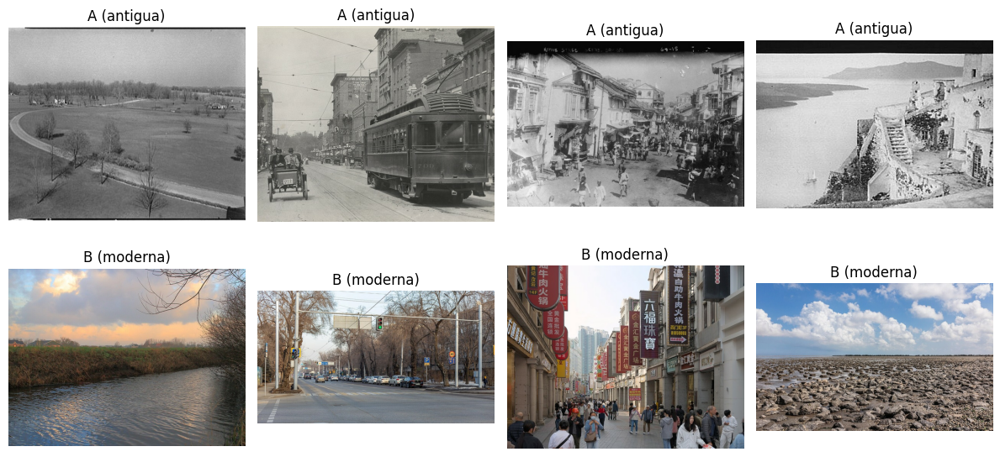

In [ ]:
# Celda 6 — Muestra visual del dataset
# Fuente: Copia_de_Gan_RED.ipynb, celda 8 (cuadrícula con plt.subplot, imshow y axis('off'));
#         Copia_de_Gan_RED.ipynb, celda 18 (savefig)
# EXCEPCIÓN F1: tf.io.read_file y tf.image.decode_image para leer las fotos.
plt.figure(figsize=(12, 6))
for i in range(4):
    for fila, (lista, titulo) in enumerate([(train_A, "A (antigua)"), (train_B, "B (moderna)")]):
        img = tf.image.decode_image(tf.io.read_file(lista[i]), channels=3, expand_animations=False)
        plt.subplot(2, 4, fila * 4 + i + 1)
        plt.imshow(img.numpy())
        plt.title(titulo)
        plt.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/muestra_dataset.png", bbox_inches="tight")
plt.show()

**Aumentación de datos (en línea, solo en entrenamiento).** El cuaderno de preparación del dataset no aumenta nada: guarda una sola copia de cada foto. La aumentación ocurre aquí, al leer cada lote, así que nunca hay copias de una foto de prueba dentro del entrenamiento.
- Ambos dominios: lado menor a 286 px sin deformar, recorte aleatorio de 256×256 y espejo horizontal al azar (es la aumentación de la CycleGAN original).
- Solo A: brillo (±0.08), contraste (0.9 a 1.1) y grano gaussiano (σ = 0.02) igual en los tres canales, para que la foto siga siendo gris.
- B no lleva ruido ni cambios de brillo: es el dominio "limpio" que el generador debe imitar.
- Prueba: sin aumentación. Recorte central cuadrado y reducción a 256×256.

No se usan rotaciones ni cambios fuertes de color. En una GAN, lo que se aumenta en las imágenes reales puede terminar copiado en las imágenes generadas.

## 3. Hiperparámetros
Se toman de la CycleGAN original (Zhu et al., 2017) y del tutorial de TensorFlow. Tasa de aprendizaje y tamaño de lote van juntos: el artículo usa lote 1 con normalización por instancia y 2e-4 con Adam (β₁ = 0.5). Por eso no se cambia uno sin el otro.

**Versión 2.** La tasa ya no es constante: baja de forma exponencial desde 2e-4 hasta 2e-5 en la última época. Generadores y discriminadores parten de la misma tasa. Se añade `LAMBDA_SUP = 10` para la pérdida supervisada, con el mismo peso que el ciclo; es un valor elegido, no ajustado.

In [ ]:
# Celda 7 — Hiperparámetros
# Fuente: Copia_de_Gan_RED.ipynb, celda 10 (Adam con beta_1 = 0.5); Copia_de_UNET.ipynb, celda 5 (tf.data.AUTOTUNE).
#         Valores de la CycleGAN original (Zhu et al., 2017) y del tutorial CycleGAN de TensorFlow,
#         enlazado en el enunciado. El suavizado de etiquetas viene de Copia_de_GAN_mnist.ipynb, celda 25.
IMG_HEIGHT = 256
IMG_WIDTH  = 256
TAM_JITTER = 286        # lado menor a 286 px y recorte aleatorio de 256x256 (aumentación)
BATCH_SIZE = 1          # lote 1, como en la CycleGAN original
LR_G       = 2e-4       # tasa inicial de los generadores
LR_D       = 2e-4       # tasa inicial de los discriminadores (el generador no la supera)
LR_FACTOR_FINAL = 0.1   # decaimiento exponencial: la tasa termina en LR x 0.1 en la última época
LAMBDA_SUP = 10.0       # peso de la pérdida supervisada (foto moderna envejecida -> original), igual al del ciclo
INTERPOLACION = "bilinear"   # subidas del generador; el primer entrenamiento usó "nearest"
BETA_1     = 0.5
LAMBDA_CYCLE = 10.0     # peso de la consistencia de ciclo
LAMBDA_ID    = 0.5      # peso de la identidad, relativo a LAMBDA_CYCLE (valor del artículo)
SUAVIZADO    = 0.1      # suavizado de etiquetas reales: 1 -> 0.9 (Copia_de_GAN_mnist)
N_RES        = 6        # bloques residuales del generador
EPOCHS       = 100      # ajustar tras medir la duración de la época 2 (la 1 incluye compilación)
MUESTRA_CADA = 5        # cada cuántas épocas guardar una imagen de progreso
AUTOTUNE = tf.data.AUTOTUNE

Lote A: (1, 256, 256, 3) | Lote B: (1, 256, 256, 3)
Prueba A: (30, 256, 256, 3) | Prueba B: (30, 256, 256, 3)
Pasos por época: 120


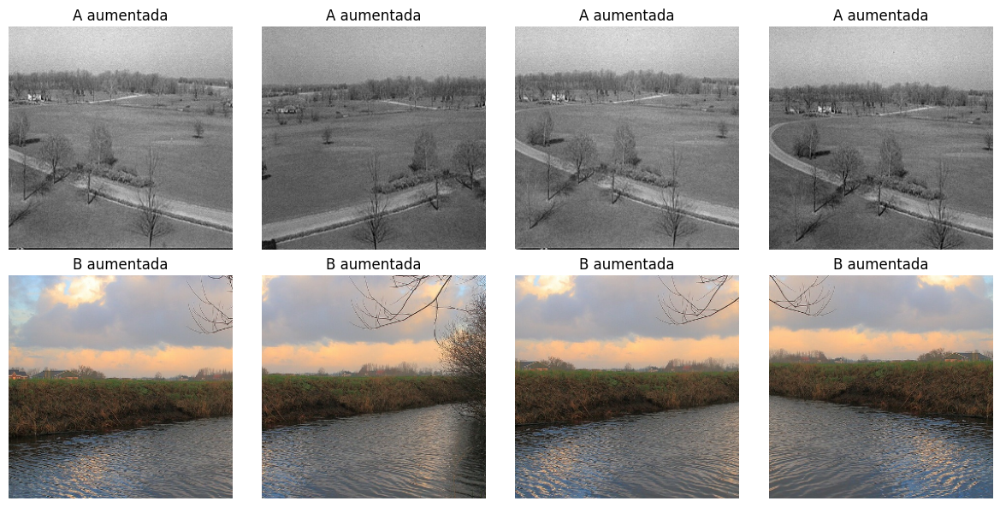

In [ ]:
# Celda 8 — Preprocesamiento y tf.data
# Fuente: Copia_de_UNET.ipynb, celda 5 (tf.image.resize, función normalize, .map y .prefetch con AUTOTUNE);
#         Copia_de_AE__1_.ipynb, celda 9 (from_tensor_slices, shuffle, batch y tf.random.normal);
#         Copia_de_Gan_RED.ipynb, celda 11 (np.stack); Copia_de_Gan_RED.ipynb, celda 8 (cuadrícula de imágenes)
# EXCEPCIÓN F1: lectura y aumentación dentro de tf.data (tf.io.read_file, decode_image, convert_image_dtype,
#         crop_to_bounding_box, random_crop, random_flip_left_right, random_brightness, random_contrast,
#         clip_by_value, tf.concat, tf.minimum, tf.math.ceil, ResizeMethod.BICUBIC). Corren dentro del grafo de
#         tf.data y dan una aumentación distinta en cada época; las alternativas del curso (cv2, load_img)
#         trabajan en NumPy fuera del grafo.
def load_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)  # gris -> 3 canales
    img = tf.image.convert_image_dtype(img, tf.float32)  # [0,1]
    return img

def recorte_cuadrado(img):
    # Recorte central cuadrado: evita deformar las fotos que no son cuadradas
    h, w = tf.shape(img)[0], tf.shape(img)[1]
    s = tf.minimum(h, w)
    return tf.image.crop_to_bounding_box(img, (h - s) // 2, (w - s) // 2, s, s)

def resize(img, h, w):
    return tf.image.resize(img, [h, w], method=tf.image.ResizeMethod.BICUBIC)

def resize_lado_menor(img, lado):
    # Lleva el lado menor a `lado` sin deformar la foto (las del dataset van de 1:1 a 2:1)
    h = tf.cast(tf.shape(img)[0], tf.float32)
    w = tf.cast(tf.shape(img)[1], tf.float32)
    f = lado / tf.minimum(h, w)
    nuevo = [tf.cast(tf.math.ceil(h * f), tf.int32), tf.cast(tf.math.ceil(w * f), tf.int32)]
    return tf.image.resize(img, nuevo, method=tf.image.ResizeMethod.BICUBIC)

def random_jitter(img):
    # El recorte aleatorio de 256x256 puede caer en cualquier parte de la foto completa:
    # en cada época el modelo ve un encuadre distinto y no se pierden los costados de las horizontales.
    img = resize_lado_menor(img, TAM_JITTER)
    img = tf.image.random_crop(img, [IMG_HEIGHT, IMG_WIDTH, 3])
    img = tf.image.random_flip_left_right(img)
    return tf.clip_by_value(img, 0.0, 1.0)   # BICUBIC puede salirse un poco de [0,1]

def small_augment(img):
    # Solo para el dominio A: el grano y las variaciones de exposición son propios de una foto vieja.
    # En B no se aplica, para no enseñarle al modelo que "moderno" incluye ruido.
    img = tf.image.random_brightness(img, max_delta=0.08)
    img = tf.image.random_contrast(img, lower=0.9, upper=1.1)
    # El ruido es el mismo en los 3 canales: una foto gris debe seguir siendo gris.
    # Ruido independiente por canal le metería puntos de color al dominio A.
    noise = tf.random.normal(tf.concat([tf.shape(img)[:2], [1]], 0), mean=0.0, stddev=0.02)
    return tf.clip_by_value(img + noise, 0.0, 1.0)

def normalize(img):
    return (img * 2.0) - 1.0   # [0,1] -> [-1,1], rango de la salida tanh

def preprocess_train_A(path):
    return normalize(small_augment(random_jitter(load_image(path))))

def preprocess_train_B(path):
    return normalize(random_jitter(load_image(path)))

def preprocess_test(path):
    img = resize(recorte_cuadrado(load_image(path)), IMG_HEIGHT, IMG_WIDTH)
    return normalize(tf.clip_by_value(img, 0.0, 1.0))

def make_dataset(lista, funcion):
    ds = tf.data.Dataset.from_tensor_slices(lista)
    ds = ds.shuffle(len(lista), seed=SEMILLA, reshuffle_each_iteration=True)
    ds = ds.map(funcion, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

trainA_ds = make_dataset(train_A, preprocess_train_A)
trainB_ds = make_dataset(train_B, preprocess_train_B)

# Conjuntos de prueba en memoria (son pocos), sin aumentación
testA = np.stack([preprocess_test(p).numpy() for p in test_A])
testB = np.stack([preprocess_test(p).numpy() for p in test_B])

print("Lote A:", next(iter(trainA_ds)).shape, "| Lote B:", next(iter(trainB_ds)).shape)
print("Prueba A:", testA.shape, "| Prueba B:", testB.shape)
print("Pasos por época:", min(len(train_A), len(train_B)) // BATCH_SIZE)

# Cuatro versiones aumentadas de la misma foto de cada dominio (la aumentación es en línea:
# cada época genera versiones nuevas y no se guardan copias en disco)
plt.figure(figsize=(12, 6))
for fila, (ruta, funcion, titulo) in enumerate([(train_A[0], preprocess_train_A, "A aumentada"),
                                                 (train_B[0], preprocess_train_B, "B aumentada")]):
    for i in range(4):
        plt.subplot(2, 4, fila * 4 + i + 1)
        plt.imshow((funcion(ruta).numpy() + 1) / 2)
        plt.title(titulo); plt.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/aumentacion.png", bbox_inches="tight")
plt.show()

## 4. Modelo
**Generador** (ResNet, 6 bloques): convolución 7×7 → dos bajadas con paso 2 → 6 bloques residuales → dos subidas → convolución 7×7 con `tanh`.
Cambios frente a la versión anterior: las subidas usan `UpSampling2D` + `Conv2D` en lugar de `Conv2DTranspose`. Con kernel 3 y paso 2, la convolución transpuesta reparte un número desigual de contribuciones entre píxeles vecinos y eso produce el patrón de tablero de ajedrez. Las convoluciones 7×7 y las de los bloques residuales usan relleno por reflexión (E7) para no crear bordes artificiales.

**Discriminador** (PatchGAN): no da un solo "real/falso", sino una rejilla de 32×32 donde cada valor juzga un parche de la imagen.

**Versión 2.** Las subidas pasan de vecino más cercano a interpolación bilineal. El resto de la arquitectura no cambia, así que los pesos del primer entrenamiento se pueden cargar para comparar.

In [ ]:
# Celda 9 — Capas propias: normalización por instancia y relleno por reflexión
# Fuente: Copia_de_Autoendores_function.ipynb, celda 7 (capa propia que hereda de Layer, con **kwargs y call)
# EXCEPCIÓN F2: normalización por instancia (add_weight, tf.nn.moments, tf.sqrt). Con lote 1, BatchNormalization
#         (Copia_de_Gan_RED.ipynb, celda 6) usa en inferencia promedios móviles distintos de los del entrenamiento.
class InstanceNormalization(layers.Layer):
    def __init__(self, epsilon=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = epsilon

    def build(self, shape):
        self.gamma = self.add_weight(shape=(shape[-1],), initializer="ones", name="gamma")
        self.beta  = self.add_weight(shape=(shape[-1],), initializer="zeros", name="beta")

    def call(self, x):
        # Normaliza cada imagen y cada canal por separado (media y varianza espaciales)
        mean, var = tf.nn.moments(x, axes=[1, 2], keepdims=True)
        return self.gamma * (x - mean) / tf.sqrt(var + self.epsilon) + self.beta

    def get_config(self):
        return {**super().get_config(), "epsilon": self.epsilon}

# EXCEPCIÓN E7: relleno por reflexión con tf.pad(mode="REFLECT"), como en la CycleGAN original.
# El relleno con ceros de padding="same" crea bordes oscuros que el generador "pinta".
class ReflectionPadding2D(layers.Layer):
    def __init__(self, padding=1, **kwargs):
        super().__init__(**kwargs)
        self.padding = padding

    def call(self, x):
        p = self.padding
        return tf.pad(x, [[0, 0], [p, p], [p, p], [0, 0]], mode="REFLECT")

    def get_config(self):
        return {**super().get_config(), "padding": self.padding}

In [ ]:
# Celda 10 — Bloques del generador
# Fuente: Copia_de_AE__1_.ipynb, celda 6 (tf.keras.Sequential); Copia_de_Gan_RED.ipynb, celda 6 (Conv2D)
# EXCEPCIÓN F4: keras.initializers.RandomNormal(stddev=0.02), inicialización de DCGAN y CycleGAN.
# EXCEPCIÓN F10: layers.ReLU como capa aparte; el curso usa activation='relu' (Copia_de_AE__1_.ipynb, celda 2).
#         Aquí la ReLU va después de la normalización, por eso no puede ir dentro de Conv2D.
init = keras.initializers.RandomNormal(stddev=0.02, seed=SEMILLA)

def downsample(filters, size):
    return keras.Sequential([
        layers.Conv2D(filters, size, strides=2, padding="same", kernel_initializer=init, use_bias=False),
        InstanceNormalization(),
        layers.ReLU(),
    ])

# Fuente: Copia_de_AE__1_.ipynb, celda 4 (UpSampling2D en el decoder del autoencoder convolucional).
# Se usa en lugar de Conv2DTranspose para evitar el patrón de tablero de ajedrez.
# EXCEPCIÓN N5: interpolation="bilinear" (el curso usa UpSampling2D con su valor por defecto, vecino más cercano).
#         La bilineal da una subida más suave; fue la recomendación del profesor para las manchas.
def upsample(filters, size, interp):
    return keras.Sequential([
        layers.UpSampling2D(size=2, interpolation=interp),
        layers.Conv2D(filters, size, padding="same", kernel_initializer=init, use_bias=False),
        InstanceNormalization(),
        layers.ReLU(),
    ])

# EXCEPCIÓN F3: layers.Add para la conexión residual. concatenate (Copia_de_UNET.ipynb, celda 7)
#         duplicaría los canales y sería otra arquitectura.
def residual_block(x, filters):
    y = ReflectionPadding2D(1)(x)
    y = layers.Conv2D(filters, 3, padding="valid", kernel_initializer=init, use_bias=False)(y)
    y = InstanceNormalization()(y)
    y = layers.ReLU()(y)
    y = ReflectionPadding2D(1)(y)
    y = layers.Conv2D(filters, 3, padding="valid", kernel_initializer=init, use_bias=False)(y)
    y = InstanceNormalization()(y)
    return layers.Add()([x, y])   # conexión residual: el bloque aprende solo la corrección

In [ ]:
# Celda 11 — Generador y discriminador
# Fuente: Copia_de_UNET.ipynb, celda 7 (API funcional con Input y Model);
#         Copia_de_Gan_RED.ipynb, celda 6 (Conv2D, LeakyReLU y summary); Copia_de_GAN_mnist.ipynb, celda 11 (Activation('tanh'));
#         Copia_de_GAN_mnist.ipynb, celdas 11 y 12 (generador y discriminador como funciones separadas)
#         Estructura ResNet y PatchGAN: tutorial CycleGAN de TensorFlow, enlazado en el enunciado.
# Usa F2 (InstanceNormalization), F4 (RandomNormal) y E7 (ReflectionPadding2D) de las celdas 9 y 10.
def build_generator(name, n_res=N_RES, interp=INTERPOLACION):
    inp = keras.Input(shape=[IMG_HEIGHT, IMG_WIDTH, 3])
    x = ReflectionPadding2D(3)(inp)
    x = layers.Conv2D(64, 7, padding="valid", kernel_initializer=init, use_bias=False)(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    x = downsample(128, 3)(x)   # 128x128
    x = downsample(256, 3)(x)   # 64x64
    for _ in range(n_res):
        x = residual_block(x, 256)
    x = upsample(128, 3, interp)(x)     # 128x128
    x = upsample(64, 3, interp)(x)      # 256x256

    x = ReflectionPadding2D(3)(x)
    x = layers.Conv2D(3, 7, padding="valid", kernel_initializer=init)(x)
    out = layers.Activation("tanh")(x)
    return keras.Model(inp, out, name=name)

def build_discriminator(name):
    inp = keras.Input(shape=[IMG_HEIGHT, IMG_WIDTH, 3])
    x = layers.Conv2D(64, 4, strides=2, padding="same", kernel_initializer=init)(inp)
    x = layers.LeakyReLU(0.2)(x)
    for f, s in [(128, 2), (256, 2), (512, 1)]:
        x = layers.Conv2D(f, 4, strides=s, padding="same", kernel_initializer=init, use_bias=False)(x)
        x = InstanceNormalization()(x)
        x = layers.LeakyReLU(0.2)(x)
    out = layers.Conv2D(1, 4, strides=1, padding="same", kernel_initializer=init)(x)   # logits por parche
    return keras.Model(inp, out, name=name)

G_A2B = build_generator("G_A2B")   # antigua -> moderna: el que restaura
G_B2A = build_generator("G_B2A")   # moderna -> antigua: solo para el ciclo
D_A = build_discriminator("D_A")   # ¿es una foto antigua real?
D_B = build_discriminator("D_B")   # ¿es una foto moderna real?

G_A2B.summary()
D_A.summary()
print("Salida del discriminador:", D_A.output_shape)

Model: "G_A2B"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reflection_padding… │ (None, 262, 262,  │          0 │ input_layer[0][0] │
│ (ReflectionPadding… │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │      9,408 │ reflection_paddi… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ instance_normaliza… │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (InstanceNormaliza… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ instance_normali… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 128, 128,  │     73,984 │ re_lu[0][0]       │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 64, 64,    │    295,424 │ sequential[0][0]  │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reflection_padding… │ (None, 66, 66,    │          0 │ sequential_1[0][… │
│ (ReflectionPadding… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    589,824 │ reflection_paddi… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ instance_normaliza… │ (None, 64, 64,    │        512 │ conv2d_3[0][0]    │
│ (InstanceNormaliza… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 64, 64,    │          0 │ instance_normali… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reflection_padding… │ (None, 66, 66,    │          0 │ re_lu_3[0][0]     │
│ (ReflectionPadding… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │    589,824 │ reflection_paddi… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ instance_normaliza… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]    │
│ (InstanceNormaliza… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ sequential_1[0][… │
│                     │ 256)              │            │ instance_normali… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reflection_padding… │ (None, 66, 66,    │          0 │ add[0][0]         │
│ (ReflectionPadding… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    589,824 │ reflection_paddi

 Total params: 7,841,411 (29.91 MB)

 Trainable params: 7,841,411 (29.91 MB)

 Non-trainable params: 0 (0.00 B)

Model: "D_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 128, 128, 64)   │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 64, 64, 128)    │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ instance_normalization_34       │ (None, 64, 64, 128)    │           256 │
│ (InstanceNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 32, 32, 256)    │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ instance_normalization_35       │ (None, 32, 32, 256)    │           512 │
│ (InstanceNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 32, 32, 512)    │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ instance_normalization_36       │ (None, 32, 32, 512)    │         1,024 │
│ (InstanceNormalization)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 32, 32, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 32, 32, 1)      │         8,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,765,633 (10.55 MB)

 Trainable params: 2,765,633 (10.55 MB)

 Non-trainable params: 0 (0.00 B)

Salida del discriminador: (None, 32, 32, 1)


In [ ]:
# Celda 12 — Funciones de pérdida y optimizadores
# Fuente: Copia_de_Semana_8_CNNs_.ipynb, celda 11 (from_logits=True); Copia_de_GAN_mnist.ipynb, celda 25
#         (suavizado de etiquetas reales); Copia_de_Gan_RED.ipynb, celda 10 (Adam con beta_1);
#         Copia_de_AE__1_.ipynb, celda 9 (tf.reduce_mean)
# EXCEPCIÓN F5: keras.losses.BinaryCrossentropy como función, tf.ones_like, tf.zeros_like y tf.abs (pérdida L1).
#         El curso usa 'binary_crossentropy' como texto en compile, que no sirve en un bucle propio.
loss_obj = keras.losses.BinaryCrossentropy(from_logits=True)

def generator_loss(fake_pred):
    # El generador quiere que el discriminador marque sus imágenes como reales (1)
    return loss_obj(tf.ones_like(fake_pred), fake_pred)

def discriminator_loss(real_pred, fake_pred):
    real_loss = loss_obj(tf.ones_like(real_pred) * (1.0 - SUAVIZADO), real_pred)
    fake_loss = loss_obj(tf.zeros_like(fake_pred), fake_pred)
    return 0.5 * (real_loss + fake_loss)   # 0.5: el discriminador aprende más despacio que G

def cycle_loss(real, cycled):
    # A -> B -> A debe devolver la foto original: obliga a conservar el contenido
    return tf.reduce_mean(tf.abs(real - cycled)) * LAMBDA_CYCLE

def identity_loss(real, same):
    # Si ya le entra una foto moderna, G_A2B no debería cambiarla
    return tf.reduce_mean(tf.abs(real - same)) * LAMBDA_CYCLE * LAMBDA_ID

# EXCEPCIÓN N2: keras.optimizers.schedules.ExponentialDecay. El curso usa una tasa fija; aquí la tasa baja de forma
#         continua desde LR hasta LR x LR_FACTOR_FINAL en la última época (pasos grandes al inicio, pequeños al final).
#         La tasa depende del contador de pasos del optimizador, que se guarda en el checkpoint: al reanudar sigue donde iba.
PASOS_TOTALES = EPOCHS * (min(len(train_A), len(train_B)) // BATCH_SIZE)

def tasa(lr_inicial):
    return keras.optimizers.schedules.ExponentialDecay(lr_inicial, decay_steps=PASOS_TOTALES, decay_rate=LR_FACTOR_FINAL)

g_opt  = keras.optimizers.Adam(tasa(LR_G), beta_1=BETA_1)   # G_A2B
f_opt  = keras.optimizers.Adam(tasa(LR_G), beta_1=BETA_1)   # G_B2A
dA_opt = keras.optimizers.Adam(tasa(LR_D), beta_1=BETA_1)   # D_A
dB_opt = keras.optimizers.Adam(tasa(LR_D), beta_1=BETA_1)   # D_B
print(f"Pasos totales: {PASOS_TOTALES} | tasa G: {LR_G:.1e} -> {LR_G * LR_FACTOR_FINAL:.1e} | tasa D: {LR_D:.1e} -> {LR_D * LR_FACTOR_FINAL:.1e}")

Pasos totales: 12000 | tasa G: 2.0e-04 -> 2.0e-05 | tasa D: 2.0e-04 -> 2.0e-05


In [ ]:
# Celda 13 — Paso de entrenamiento
# Fuente: Copia_de_AE__1_.ipynb, celda 9 (@tf.function, tf.GradientTape y apply_gradients en el CVAE)
# EXCEPCIÓN F5: GradientTape(persistent=True), un solo tape para sacar los gradientes de las cuatro redes.
# EXCEPCIÓN N1: pérdida supervisada con envejecimiento sintético. Cada foto moderna se envejece al vuelo y se le pide
#         a G_A2B que devuelva la original (L1). Es la idea de pix2pix aplicada a pares fabricados, y le enseña a quitar
#         desenfoque y ruido, que el primer entrenamiento no aprendió (celda 23). Usa las funciones de S2 más
#         tf.random.uniform. Los parámetros se sortean en cada paso dentro de un rango que contiene a los de la prueba
#         de la celda 19; las fotos de prueba siguen sin verse en entrenamiento.
def kernel_gaussiano(tam=5, sigma=1.0):
    eje = tf.range(tam, dtype=tf.float32) - (tam - 1) / 2
    g = tf.exp(-(eje ** 2) / (2 * sigma ** 2))
    k = tf.tensordot(g, g, axes=0)
    k = k / tf.reduce_sum(k)
    return tf.tile(k[:, :, None, None], [1, 1, 3, 1])   # un kernel por canal

def envejecer(lote):
    # lote en [-1,1] -> gris -> tono entre gris y sepia -> desenfoque -> menos contraste -> ruido -> [-1,1]
    x = (lote + 1.0) / 2.0
    gris = tf.image.rgb_to_grayscale(x)
    tono = 1.0 - tf.random.uniform([]) * (1.0 - tf.constant([1.0, 0.89, 0.71]))
    borrosa = tf.nn.depthwise_conv2d(gris * tono, kernel_gaussiano(5, tf.random.uniform([], 0.5, 1.5)),
                                     strides=[1, 1, 1, 1], padding="SAME")
    plana = tf.image.adjust_contrast(borrosa, tf.random.uniform([], 0.6, 1.0))
    ruido = tf.random.normal(tf.shape(plana), stddev=tf.random.uniform([], 0.01, 0.06))
    return tf.clip_by_value(plana + ruido, 0.0, 1.0) * 2.0 - 1.0

@tf.function
def train_step(real_A, real_B):
    vieja_B = envejecer(real_B)
    with tf.GradientTape(persistent=True) as tape:
        fake_B = G_A2B(real_A, training=True)
        fake_A = G_B2A(real_B, training=True)
        cycled_A = G_B2A(fake_B, training=True)
        cycled_B = G_A2B(fake_A, training=True)
        same_A = G_B2A(real_A, training=True)
        same_B = G_A2B(real_B, training=True)
        rest_B = G_A2B(vieja_B, training=True)   # foto moderna envejecida -> restaurada

        D_A_real = D_A(real_A, training=True)
        D_A_fake = D_A(fake_A, training=True)
        D_B_real = D_B(real_B, training=True)
        D_B_fake = D_B(fake_B, training=True)

        gA2B_adv = generator_loss(D_B_fake)
        gB2A_adv = generator_loss(D_A_fake)
        cyc = cycle_loss(real_A, cycled_A) + cycle_loss(real_B, cycled_B)
        sup = tf.reduce_mean(tf.abs(real_B - rest_B)) * LAMBDA_SUP
        total_gA2B = gA2B_adv + cyc + identity_loss(real_B, same_B) + sup
        total_gB2A = gB2A_adv + cyc + identity_loss(real_A, same_A)

        dA_loss = discriminator_loss(D_A_real, D_A_fake)
        dB_loss = discriminator_loss(D_B_real, D_B_fake)

    g_opt.apply_gradients(zip(tape.gradient(total_gA2B, G_A2B.trainable_variables), G_A2B.trainable_variables))
    f_opt.apply_gradients(zip(tape.gradient(total_gB2A, G_B2A.trainable_variables), G_B2A.trainable_variables))
    dA_opt.apply_gradients(zip(tape.gradient(dA_loss, D_A.trainable_variables), D_A.trainable_variables))
    dB_opt.apply_gradients(zip(tape.gradient(dB_loss, D_B.trainable_variables), D_B.trainable_variables))
    del tape
    return dA_loss, dB_loss, gA2B_adv, gB2A_adv, cyc, sup

## 5. Entrenamiento

**Versión 2.** En cada paso la foto moderna se envejece de forma sintética (gris o sepia, desenfoque, menos contraste y ruido, con parámetros sorteados) y `G_A2B` debe devolver la original. Es una pérdida supervisada L1 que se suma a las de la CycleGAN. Los tres cambios (pérdida supervisada, decaimiento de la tasa e interpolación bilineal) se entrenan juntos, de modo que la mejora o el deterioro frente a la v1 no se puede atribuir a uno solo.

In [ ]:
# Celda 14 — Checkpoints (permiten continuar si Colab se desconecta)
# Fuente: Copia_de_Semana4_MLP_Tensorboard.ipynb, celda 20 (ModelCheckpoint, guardar en cada época)
# EXCEPCIÓN F6: tf.train.Checkpoint y CheckpointManager. ModelCheckpoint es un callback de model.fit y el
#         bucle propio no lo llama; estos guardan los cuatro modelos y los cuatro optimizadores para reanudar.
ckpt = tf.train.Checkpoint(G_A2B=G_A2B, G_B2A=G_B2A, D_A=D_A, D_B=D_B,
                           g_opt=g_opt, f_opt=f_opt, dA_opt=dA_opt, dB_opt=dB_opt,
                           epoch=tf.Variable(0))
ckpt_manager = tf.train.CheckpointManager(ckpt, CKPT_DIR, max_to_keep=3)

if ENTRENAR and ckpt_manager.latest_checkpoint:
    ckpt.restore(ckpt_manager.latest_checkpoint)
    print("Continuando desde", ckpt_manager.latest_checkpoint, "| épocas ya hechas:", int(ckpt.epoch.numpy()))
elif ENTRENAR:
    print("No hay checkpoint previo: se entrena desde cero.")

In [ ]:
# Celda 15 — Bucle de entrenamiento (solo si ENTRENAR = True)
# Fuente: Copia_de_GAN_mnist.ipynb, celda 25 (bucle por épocas con losses.append); Copia_de_AE__1_.ipynb,
#         celda 9 (time.time por época); Copia_de_Gan_RED.ipynb, celda 18 (guardar figuras de progreso con savefig);
#         Copia_de_Semana_8_CNNs_.ipynb, celda 16 (load_weights); Copia_de_Autoendores_function.ipynb, celda 3 (read_csv)
# EXCEPCIÓN F8: tf.data.Dataset.zip para formar los pares (lote A, lote B).
# EXCEPCIÓN F7: save_weights (.weights.h5).
# EXCEPCIÓN F10: to_csv, to_dict y os.path.exists.
COLUMNAS = ["D_A", "D_B", "G_A2B_adv", "G_B2A_adv", "ciclo", "supervisada"]
muestra_fija = testA[:1]   # misma foto de prueba en cada época para ver el progreso

def guardar_muestra(epoca):
    salida = G_A2B(muestra_fija, training=False).numpy()
    fig, ax = plt.subplots(1, 2, figsize=(6, 3))
    for a, img, t in zip(ax, [muestra_fija[0], salida[0]], ["Antigua (prueba)", f"Restaurada, época {epoca}"]):
        a.imshow((img + 1) / 2); a.set_title(t); a.axis("off")
    fig.savefig(f"{RESULT_DIR}/progreso/epoca_{epoca:03d}.png", bbox_inches="tight")
    plt.close(fig)

def guardar_pesos(etiqueta):
    G_A2B.save_weights(PESOS[f"{etiqueta}_A2B"])
    G_B2A.save_weights(PESOS[f"{etiqueta}_B2A"])

if ENTRENAR:
    inicio = int(ckpt.epoch.numpy())
    historial = []
    if inicio > 0 and os.path.exists(HISTORIAL_CSV):
        historial = [f for f in pd.read_csv(HISTORIAL_CSV).to_dict("records") if f["epoca"] <= inicio]

    for epoch in range(inicio, EPOCHS):
        t0 = time.time()
        perdidas = []
        for real_A, real_B in tf.data.Dataset.zip((trainA_ds, trainB_ds)):
            perdidas.append([float(v) for v in train_step(real_A, real_B)])
        duracion = time.time() - t0

        media = np.mean(perdidas, axis=0)
        historial.append({"epoca": epoch + 1, **dict(zip(COLUMNAS, media)), "segundos": duracion,
                          "compila": epoch == inicio})   # primera época de la sesión: incluye compilación

        ckpt.epoch.assign(epoch + 1)
        ckpt_manager.save()
        pd.DataFrame(historial).to_csv(HISTORIAL_CSV, index=False)
        if epoch + 1 == EPOCHS // 2:
            guardar_pesos("mitad")
        if (epoch + 1) % MUESTRA_CADA == 0 or epoch == inicio:
            guardar_muestra(epoch + 1)

        nota = "  (incluye compilación de tf.function)" if epoch == inicio else ""
        print(f"Época {epoch+1}/{EPOCHS} | {duracion:.1f} s{nota} | D_A={media[0]:.3f} D_B={media[1]:.3f} | "
              f"G_A2B={media[2]:.3f} G_B2A={media[3]:.3f} | ciclo={media[4]:.3f} | sup={media[5]:.3f}")

    guardar_pesos("final")
    print("Pesos finales guardados en", MODELOS_DIR)
else:
    if not os.path.exists(PESOS["final_A2B"]):
        raise FileNotFoundError("No hay pesos guardados. Pongan ENTRENAR = True en la celda 2 y entrenen primero.")
    G_A2B.load_weights(PESOS["final_A2B"])
    G_B2A.load_weights(PESOS["final_B2A"])
    print("Pesos finales cargados desde", MODELOS_DIR)

Pesos finales cargados desde /content/drive/MyDrive/CycleGAN/models_restore_v2


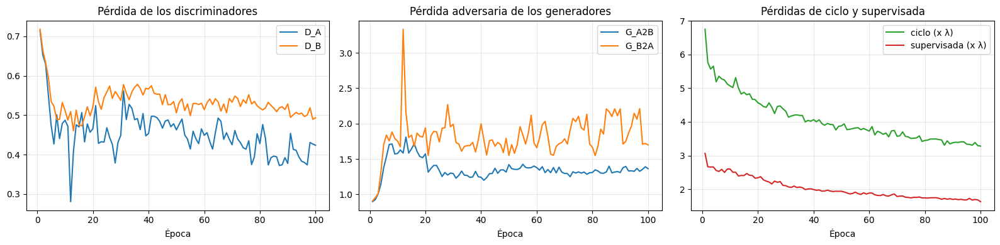

Épocas registradas: 100 | tiempo por época (sin calentamiento, n=99): media 97.8 s, desviación 10.3 s | total 163.6 min


In [ ]:
# Celda 16 — Curvas de pérdida y tiempo por época
# Fuente: Copia_de_GAN_mnist.ipynb, celda 26 (gráfica de pérdidas del discriminador y el generador);
#         Copie_de_Semana_3_Concrete_Compressive_Strength_RNA_1_1.ipynb, celda 16 (subplots y tight_layout);
#         Copia_de_Autoendores_function.ipynb, celda 3 (read_csv)
# EXCEPCIÓN F10: métodos mean y std de pandas.
hist = pd.read_csv(HISTORIAL_CSV)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(hist.epoca, hist.D_A, label="D_A"); ax[0].plot(hist.epoca, hist.D_B, label="D_B")
ax[0].set_title("Pérdida de los discriminadores")
ax[1].plot(hist.epoca, hist.G_A2B_adv, label="G_A2B"); ax[1].plot(hist.epoca, hist.G_B2A_adv, label="G_B2A")
ax[1].set_title("Pérdida adversaria de los generadores")
ax[2].plot(hist.epoca, hist.ciclo, label="ciclo (x λ)", color="tab:green")
ax[2].plot(hist.epoca, hist.supervisada, label="supervisada (x λ)", color="tab:red")
ax[2].set_title("Pérdidas de ciclo y supervisada")
for a in ax:
    a.set_xlabel("Época"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/curvas_perdida.png", bbox_inches="tight")
plt.show()

# La primera época de cada sesión incluye la compilación del grafo (calentamiento); se excluye del promedio.
t = hist.segundos[~hist.compila.astype(bool)]
if len(t) == 0:
    t = hist.segundos
print(f"Épocas registradas: {len(hist)} | tiempo por época (sin calentamiento, n={len(t)}): "
      f"media {t.mean():.1f} s, desviación {t.std():.1f} s | total {hist.segundos.sum()/60:.1f} min")

## 6. Evaluación en el conjunto de prueba
Una CycleGAN no pareada no tiene "la foto restaurada correcta", así que se usan tres medidas que miran cosas distintas:
1. **Error de ciclo L1** (A → B → A): ¿el modelo conserva el contenido de la foto?
2. **PSNR y SSIM sobre degradación sintética** (E1): fotos modernas de prueba envejecidas a propósito, restauradas y comparadas con su original. Limitación: esta degradación no es igual al envejecimiento real.
3. **KID** (E3): distancia entre las características InceptionV3 de las fotos restauradas y las de fotos modernas reales. Mide si el resultado *parece* moderno, que es lo que optimiza la GAN. Menor es mejor.

Se comparan la **línea base de identidad** (devolver la entrada sin tocarla), el modelo a la **mitad** del entrenamiento y el modelo **final**.

**Versión 2.** Se añaden FID, Inception Score y precisión-recuperación (celda 20b), y la comparación incluye el primer entrenamiento (v1). Con 30 fotos por grupo estas tres medidas son ruidosas; por eso cada una se acompaña de una referencia calculada entre fotos modernas reales.

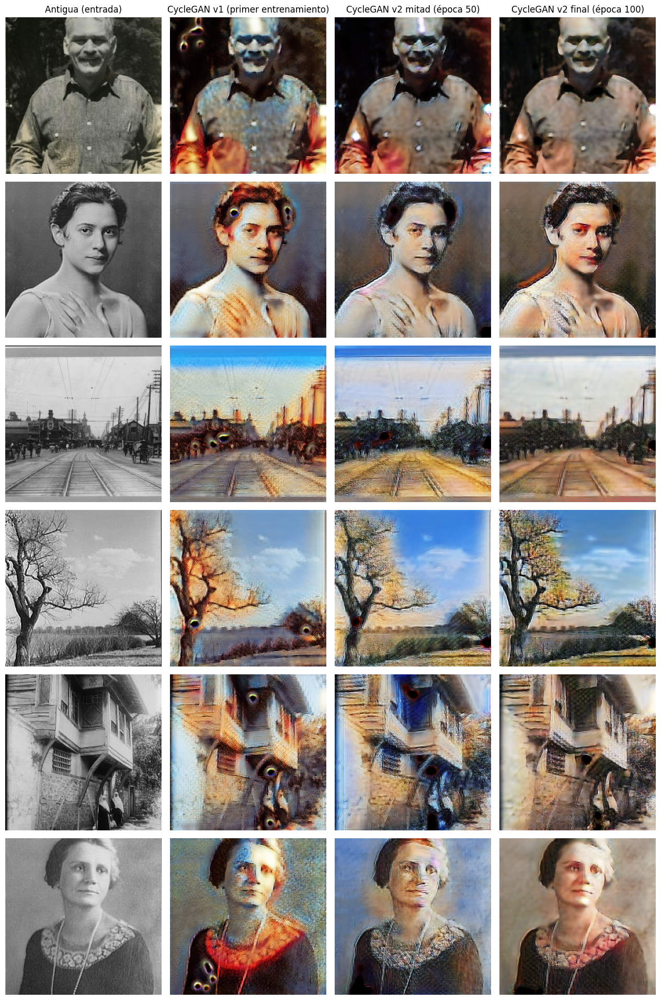

In [ ]:
# Celda 17 — Modelos a comparar y función de inferencia
# Fuente: Copia_de_Gan_RED.ipynb, celda 7 (predict del generador e imshow); Copia_de_Semana_8_CNNs_.ipynb,
#         celda 16 (load_weights); Copia_de_GAN_mnist.ipynb, celda 18 (np.clip); Copia_de_Gan_RED.ipynb, celda 8 (cuadrícula)
def a01(x):
    return np.clip((x + 1.0) / 2.0, 0.0, 1.0)   # [-1,1] -> [0,1]

def cargar_generadores(etiqueta):
    ga, gb = build_generator(f"A2B_{etiqueta}"), build_generator(f"B2A_{etiqueta}")
    ga.load_weights(PESOS[f"{etiqueta}_A2B"])
    gb.load_weights(PESOS[f"{etiqueta}_B2A"])
    return ga, gb

modelos = {f"CycleGAN v2 final (época {EPOCHS})": (G_A2B, G_B2A)}
if os.path.exists(PESOS["mitad_A2B"]):
    modelos = {f"CycleGAN v2 mitad (época {EPOCHS//2})": cargar_generadores("mitad"), **modelos}
else:
    print("No hay pesos de la mitad del entrenamiento; se compara solo el modelo final.")

# Primer entrenamiento (v1): misma arquitectura con subida por vecino más cercano; sirve de punto de comparación.
if os.path.exists(PESOS_V1["A2B"]):
    g1a, g1b = build_generator("A2B_v1", interp="nearest"), build_generator("B2A_v1", interp="nearest")
    g1a.load_weights(PESOS_V1["A2B"]); g1b.load_weights(PESOS_V1["B2A"])
    modelos = {"CycleGAN v1 (primer entrenamiento)": (g1a, g1b), **modelos}
else:
    print("No están los pesos del primer entrenamiento; no se incluye en la comparación.")

def restaurar(G, x):
    return G.predict(x, batch_size=4, verbose=0)

# Resultados visuales en fotos antiguas de prueba (nunca vistas en entrenamiento)
n = min(6, len(testA))
salidas = {nombre: restaurar(ga, testA[:n]) for nombre, (ga, _) in modelos.items()}
columnas = ["Antigua (entrada)"] + list(salidas)
fig, ax = plt.subplots(n, len(columnas), figsize=(3.2 * len(columnas), 3.2 * n), squeeze=False)
for i in range(n):
    imgs = [testA[i]] + [s[i] for s in salidas.values()]
    for j, (img, titulo) in enumerate(zip(imgs, columnas)):
        ax[i, j].imshow(a01(img)); ax[i, j].axis("off")
        if i == 0: ax[i, j].set_title(titulo)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/resultados_prueba_A.png", bbox_inches="tight")
plt.show()

In [ ]:
# Celda 18 — Métrica 1: error de ciclo L1 en prueba
# Fuente: Copia_de_Gan_RED.ipynb, celda 7 (predict); Copia_de_Autoendores_function.ipynb, celda 12 (np.mean).
#         Es la pérdida de ciclo de la celda 12, sin el factor λ y en escala [0,1].
# EXCEPCIÓN F10: np.abs.
resultados = {nombre: {} for nombre in ["Línea base (identidad)"] + list(modelos)}

for nombre, (ga, gb) in modelos.items():
    ciclo_A = restaurar(gb, restaurar(ga, testA))
    ciclo_B = restaurar(ga, restaurar(gb, testB))
    resultados[nombre]["Ciclo L1 A→B→A"] = np.mean(np.abs(a01(testA) - a01(ciclo_A)))
    resultados[nombre]["Ciclo L1 B→A→B"] = np.mean(np.abs(a01(testB) - a01(ciclo_B)))
    print(f"{nombre}: ciclo A={resultados[nombre]['Ciclo L1 A→B→A']:.4f} | "
          f"ciclo B={resultados[nombre]['Ciclo L1 B→A→B']:.4f}")

CycleGAN v1 (primer entrenamiento): ciclo A=0.0802 | ciclo B=0.1008
CycleGAN v2 mitad (época 50): ciclo A=0.0826 | ciclo B=0.1049
CycleGAN v2 final (época 100): ciclo A=0.0717 | ciclo B=0.0984


Línea base (identidad): PSNR=15.48 ± 1.65 dB | SSIM=0.369 ± 0.062
CycleGAN v1 (primer entrenamiento): PSNR=15.85 ± 1.53 dB | SSIM=0.397 ± 0.068
CycleGAN v2 mitad (época 50): PSNR=17.68 ± 1.80 dB | SSIM=0.556 ± 0.101
CycleGAN v2 final (época 100): PSNR=18.15 ± 1.93 dB | SSIM=0.572 ± 0.100


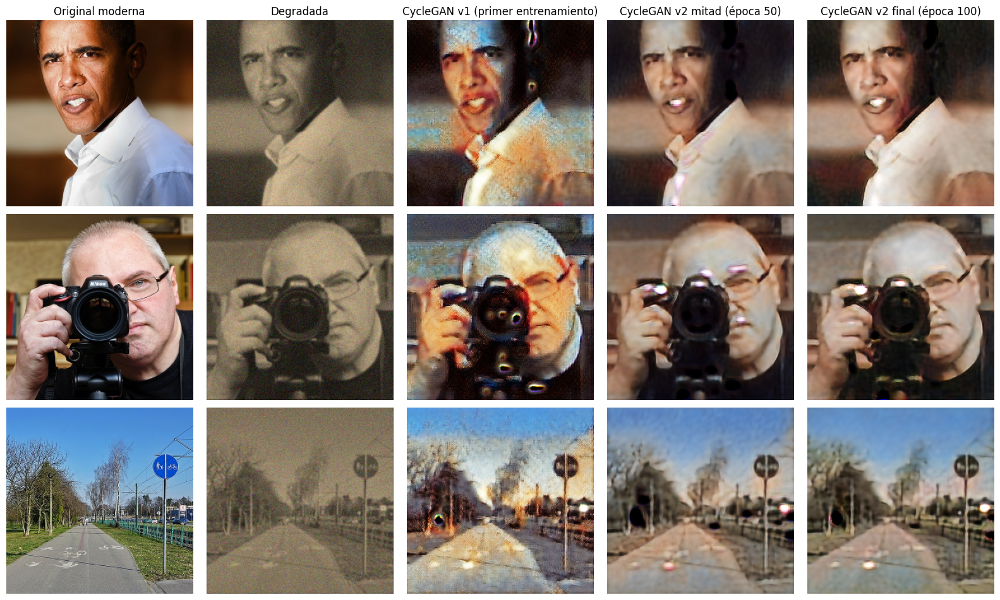

In [ ]:
# Celda 19 — Métrica 2: PSNR y SSIM sobre fotos modernas degradadas
# Fuente: Copia_de_Gan_RED.ipynb, celda 11 (np.stack); Copia_de_Gan_RED.ipynb, celda 8 (cuadrícula de imágenes)
# EXCEPCIÓN E1: tf.image.psnr y tf.image.ssim. Sin un par entrada/verdad no se puede medir la
#         restauración con un número; la degradación sintética crea ese par a partir de las fotos modernas de prueba.
# EXCEPCIÓN S2: la degradación usa tf.image.rgb_to_grayscale, tf.nn.depthwise_conv2d, tf.image.adjust_contrast,
#         tf.random.stateless_normal, tf.range, tf.tensordot, tf.tile y tf.constant. La alternativa del curso es
#         cv2.cvtColor y cv2.GaussianBlur (Copia_de_Semana_8_CNNs_.ipynb, celda 1).
# EXCEPCIÓN F10: np.std.
# kernel_gaussiano está en la celda 13. Desde la v2 el generador entrena con envejecimientos de este mismo tipo
# (con parámetros sorteados), así que esta prueba mide un daño conocido en fotos que nunca vio.
KERNEL = kernel_gaussiano()

def degradar(img01, semilla):
    # Envejecimiento sintético: gris -> tono sepia -> desenfoque -> menos contraste -> ruido
    gris = tf.image.rgb_to_grayscale(img01)
    sepia = gris * tf.constant([1.0, 0.89, 0.71])
    borrosa = tf.nn.depthwise_conv2d(sepia[None], KERNEL, strides=[1, 1, 1, 1], padding="SAME")[0]
    plana = tf.image.adjust_contrast(borrosa, 0.7)
    ruido = tf.random.stateless_normal(tf.shape(plana), seed=[SEMILLA, semilla], stddev=0.04)
    return tf.clip_by_value(plana + ruido, 0.0, 1.0)

originales = a01(testB).astype(np.float32)
degradadas = np.stack([degradar(img, i).numpy() for i, img in enumerate(originales)])
entrada = degradadas * 2.0 - 1.0

salidas_deg = {"Línea base (identidad)": degradadas}
for nombre, (ga, _) in modelos.items():
    salidas_deg[nombre] = a01(restaurar(ga, entrada))

for nombre, sal in salidas_deg.items():
    psnr = tf.image.psnr(sal, originales, max_val=1.0).numpy()
    ssim = tf.image.ssim(tf.constant(sal), tf.constant(originales), max_val=1.0).numpy()
    resultados[nombre]["PSNR (dB)"] = psnr.mean(); resultados[nombre]["PSNR desv."] = psnr.std()
    resultados[nombre]["SSIM"] = ssim.mean();      resultados[nombre]["SSIM desv."] = ssim.std()
    print(f"{nombre}: PSNR={psnr.mean():.2f} ± {psnr.std():.2f} dB | SSIM={ssim.mean():.3f} ± {ssim.std():.3f}")

n = min(3, len(originales))
cols = ["Original moderna", "Degradada"] + [k for k in salidas_deg if k != "Línea base (identidad)"]
fig, ax = plt.subplots(n, len(cols), figsize=(3.2 * len(cols), 3.2 * n), squeeze=False)
for i in range(n):
    imgs = [originales[i], degradadas[i]] + [salidas_deg[k][i] for k in cols[2:]]
    for j, (img, t) in enumerate(zip(imgs, cols)):
        ax[i, j].imshow(img); ax[i, j].axis("off")
        if i == 0: ax[i, j].set_title(t)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/degradacion_sintetica.png", bbox_inches="tight")
plt.show()

In [ ]:
# Celda 20 — Métrica 3: KID (Kernel Inception Distance)
# Fuente: Copia_de_DETECTOR_DE_OBJETOS.ipynb, celda 34 (keras.applications.VGG16 con weights='imagenet' e
#         include_top=False); Copia_de_GAN_mnist.ipynb, celda 25 (np.random.choice)
# EXCEPCIÓN E3: InceptionV3 preentrenada en ImageNet como extractor de características, con su preprocess_input.
#         Se usa KID y no FID porque FID tiene mucho sesgo con unas decenas de imágenes; KID es insesgado.
# EXCEPCIÓN S3: np.random.default_rng y np.trace (la alternativa del curso es np.random.seed + np.random.choice).
# EXCEPCIÓN F10: np.std.
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input

inception = InceptionV3(include_top=False, pooling="avg", weights="imagenet", input_shape=(299, 299, 3))

def caracteristicas(imgs01):
    x = tf.image.resize(np.asarray(imgs01) * 255.0, [299, 299])
    return inception.predict(preprocess_input(x), batch_size=16, verbose=0).astype(np.float64)

def kid(f1, f2):
    # MMD² insesgado con kernel polinomial k(x,y) = (x·y/d + 1)^3
    d = f1.shape[1]
    kxx = (f1 @ f1.T / d + 1) ** 3
    kyy = (f2 @ f2.T / d + 1) ** 3
    kxy = (f1 @ f2.T / d + 1) ** 3
    m, n = len(f1), len(f2)
    return ((kxx.sum() - np.trace(kxx)) / (m * (m - 1)) +
            (kyy.sum() - np.trace(kyy)) / (n * (n - 1)) - 2 * kxy.mean())

def kid_subconjuntos(f1, f2, repeticiones=20, fraccion=0.8):
    rng = np.random.default_rng(SEMILLA)
    s = max(2, int(fraccion * min(len(f1), len(f2))))
    v = [kid(f1[rng.choice(len(f1), s, replace=False)], f2[rng.choice(len(f2), s, replace=False)])
         for _ in range(repeticiones)]
    return 1000 * np.mean(v), 1000 * np.std(v)   # se reporta KID x 10^3, como es costumbre

f_testB = caracteristicas(a01(testB))
conjuntos = {"Línea base (identidad)": a01(testA)}
for nombre, (ga, _) in modelos.items():
    conjuntos[nombre] = a01(restaurar(ga, testA))

for nombre, imgs in conjuntos.items():
    media, desv = kid_subconjuntos(caracteristicas(imgs), f_testB)
    resultados[nombre]["KID x10³"] = media; resultados[nombre]["KID desv."] = desv
    print(f"{nombre}: KID x10³ = {media:.2f} ± {desv:.2f}")

# Referencia: dos grupos de fotos modernas reales. Es el piso que se puede esperar con estas muestras.
muestra_trainB = np.stack([a01(preprocess_test(p).numpy()) for p in train_B[:len(test_B) * 2]])
ref = kid_subconjuntos(caracteristicas(muestra_trainB), f_testB)
resultados["Referencia: B entrenamiento vs B prueba"] = {"KID x10³": ref[0], "KID desv.": ref[1]}
print(f"Referencia real vs real: KID x10³ = {ref[0]:.2f} ± {ref[1]:.2f}  (KID insesgado puede salir levemente negativo)")

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Línea base (identidad): KID x10³ = 81.82 ± 4.07
CycleGAN v1 (primer entrenamiento): KID x10³ = 102.75 ± 7.05
CycleGAN v2 mitad (época 50): KID x10³ = 75.90 ± 6.43
CycleGAN v2 final (época 100): KID x10³ = 67.23 ± 3.32
Referencia real vs real: KID x10³ = -2.73 ± 2.97  (KID insesgado puede salir levemente negativo)


In [ ]:
# Celda 20b — Métricas pedidas por el profesor: FID, Inception Score y precisión-recuperación
# Fuente: Celda 20 de este cuaderno (caracteristicas de InceptionV3, conjuntos, muestra_trainB);
#         Copia_de_Autoendores_function.ipynb, celdas 3 y 12 (np.sum, np.mean).
# EXCEPCIÓN N3: FID con np.cov y scipy.linalg.sqrtm. Compara media y covarianza de las características de Inception
#         entre fotos generadas y reales. Con 30 fotos la covarianza (2048x2048) queda mal estimada y el FID sale
#         inflado; por eso se da también el valor entre dos grupos de fotos reales, que es el piso alcanzable aquí.
# EXCEPCIÓN N4: Inception Score con InceptionV3 completa (include_top=True), np.log y np.exp. Mide si cada imagen se
#         clasifica con seguridad y si el conjunto es variado. No compara contra fotos reales.
# EXCEPCIÓN N6: precisión y recuperación (Kynkäänniemi et al., 2019) con np.sort. Precisión: fracción de generadas
#         que caen cerca de alguna real (calidad). Recuperación: fracción de reales con alguna generada cerca (variedad).
from scipy import linalg

clasificador = InceptionV3(include_top=True, weights="imagenet")

def fid(f1, f2):
    mu1, mu2 = np.mean(f1, axis=0), np.mean(f2, axis=0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    raiz = linalg.sqrtm(s1 @ s2).real          # raíz matricial; la parte imaginaria es error numérico
    return np.sum((mu1 - mu2) ** 2) + np.trace(s1 + s2 - 2 * raiz)

def inception_score(imgs01):
    x = tf.image.resize(np.asarray(imgs01) * 255.0, [299, 299])
    p = clasificador.predict(preprocess_input(x), batch_size=16, verbose=0).astype(np.float64)   # p(clase | imagen)
    p_media = np.mean(p, axis=0)                                                                  # p(clase)
    kl = np.sum(p * (np.log(p + 1e-12) - np.log(p_media + 1e-12)), axis=1)
    return np.exp(np.mean(kl))

def distancias2(a, b):
    return np.sum(a ** 2, axis=1)[:, None] + np.sum(b ** 2, axis=1)[None, :] - 2 * a @ b.T

def cobertura(f_ref, f_eval, k=3):
    # Fracción de f_eval que cae dentro del radio al k-ésimo vecino de alguna muestra de f_ref
    radio = np.sort(distancias2(f_ref, f_ref), axis=1)[:, k]     # columna 0 = la propia muestra
    dentro = distancias2(f_eval, f_ref) <= radio[None, :]
    return np.mean(np.sum(dentro, axis=1) > 0)

for nombre, imgs in conjuntos.items():
    f = caracteristicas(imgs)
    r = resultados[nombre]
    r["FID"] = fid(f, f_testB); r["IS"] = inception_score(imgs)
    r["Precisión"] = cobertura(f_testB, f); r["Recuperación"] = cobertura(f, f_testB)
    print(f"{nombre}: FID={r['FID']:.1f} | IS={r['IS']:.2f} | precisión={r['Precisión']:.2f} | recuperación={r['Recuperación']:.2f}")

# Referencia entre fotos modernas reales (entrenamiento vs prueba): lo mejor que pueden dar estas medidas con estas muestras
f_ref = caracteristicas(muestra_trainB)
r = resultados["Referencia: B entrenamiento vs B prueba"]
r["FID"] = fid(f_ref, f_testB); r["IS"] = inception_score(a01(testB))
r["Precisión"] = cobertura(f_testB, f_ref); r["Recuperación"] = cobertura(f_ref, f_testB)
print(f"Referencia real vs real: FID={r['FID']:.1f} | IS (fotos modernas de prueba)={r['IS']:.2f} | "
      f"precisión={r['Precisión']:.2f} | recuperación={r['Recuperación']:.2f}")

96112376/96112376 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Línea base (identidad): FID=319.5 | IS=7.66 | precisión=0.20 | recuperación=0.63
CycleGAN v1 (primer entrenamiento): FID=343.6 | IS=3.91 | precisión=0.30 | recuperación=0.17
CycleGAN v2 mitad (época 50): FID=329.0 | IS=5.56 | precisión=0.40 | recuperación=0.27
CycleGAN v2 final (época 100): FID=306.8 | IS=4.45 | precisión=0.43 | recuperación=0.40
Referencia real vs real: FID=223.0 | IS (fotos modernas de prueba)=7.81 | precisión=0.82 | recuperación=0.80


## 7. Comparación

In [ ]:
# Celda 21 — Tabla resumen (todas las cifras del informe y del pitch salen de aquí)
# Fuente: Copie_de_Semana_3_Concrete_Compressive_Strength_RNA_1_1.ipynb, celda 3 (pandas DataFrame);
#         Copie_de_Semana_2.ipynb, celda 21 (round)
# EXCEPCIÓN F10: transpuesta .T del DataFrame y to_csv.
tabla = pd.DataFrame(resultados).T
orden = ["Ciclo L1 A→B→A", "Ciclo L1 B→A→B", "PSNR (dB)", "PSNR desv.", "SSIM", "SSIM desv.", "KID x10³", "KID desv.",
         "FID", "IS", "Precisión", "Recuperación"]
tabla = tabla[[c for c in orden if c in tabla.columns]]
tabla.to_csv(f"{RESULT_DIR}/tabla_metricas.csv")
print("Conjunto de prueba:", len(test_A), "fotos antiguas y", len(test_B), "modernas")
print("Ciclo L1, KID y FID: menor es mejor | PSNR, SSIM, IS, precisión y recuperación: mayor es mejor")
tabla.round(4)

Conjunto de prueba: 30 fotos antiguas y 30 modernas
Ciclo L1, KID y FID: menor es mejor | PSNR, SSIM, IS, precisión y recuperación: mayor es mejor


,Ciclo L1 A→B→A,Ciclo L1 B→A→B,PSNR (dB),PSNR desv.,SSIM,SSIM desv.,KID x10³,KID desv.,FID,IS,Precisión,Recuperación
Línea base (identidad),NaN,NaN,15.4762,1.6526,0.3691,0.0617,81.8224,4.0662,319.5489,7.6621,0.2000,0.6333
CycleGAN v1 (primer entrenamiento),0.0802,0.1008,15.8546,1.5273,0.3974,0.0684,102.7496,7.0453,343.5542,3.9107,0.3000,0.1667
CycleGAN v2 mitad (época 50),0.0826,0.1049,17.6835,1.8044,0.5565,0.1013,75.9023,6.4331,328.9591,5.5589,0.4000,0.2667
CycleGAN v2 final (época 100),0.0717,0.0984,18.1488,1.9254,0.5722,0.0998,67.2322,3.3219,306.7791,4.4495,0.4333,0.4000
Referencia: B entrenamiento vs B prueba,NaN,NaN,NaN,NaN,NaN,NaN,-2.7339,2.9710,223.0105,7.8089,0.8167,0.8000


## 8. Prueba con datos propios

Saving Nautch-Girl---Circa-1860s.jpg to Nautch-Girl---Circa-1860s (1).jpg


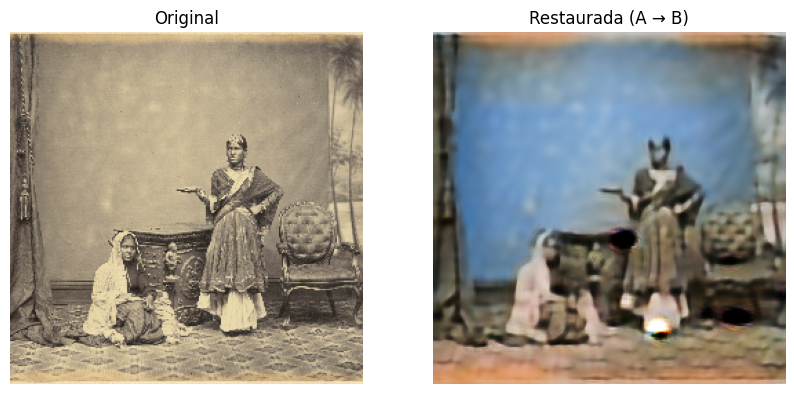

In [ ]:
# Celda 22 — Subir fotos propias y restaurarlas
# Fuente: Copia_de_DETECTOR_DE_OBJETOS.ipynb, celda 7 (from google.colab import files) y celda 28 (Path(...).stem);
#         Copia_de_Gan_RED.ipynb, celda 18 (savefig)
# EXCEPCIÓN E4: files.upload() para subir fotos durante la sustentación.
# EXCEPCIÓN F1: decode_image, convert_image_dtype y clip_by_value, con las mismas funciones de la celda 8.
from google.colab import files

subidas = files.upload()
for nombre, datos in subidas.items():
    try:
        img = tf.image.decode_image(datos, channels=3, expand_animations=False)
    except Exception:
        print(f"{nombre}: no es una imagen válida, se omite.")
        continue
    img = tf.image.convert_image_dtype(img, tf.float32)
    x = normalize(tf.clip_by_value(resize(recorte_cuadrado(img), IMG_HEIGHT, IMG_WIDTH), 0.0, 1.0))[None]
    salida = a01(G_A2B(x, training=False).numpy()[0])

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(a01(x[0].numpy())); ax[0].set_title("Original"); ax[0].axis("off")
    ax[1].imshow(salida); ax[1].set_title("Restaurada (A → B)"); ax[1].axis("off")
    fig.savefig(f"{RESULT_DIR}/propias/{Path(nombre).stem}_restaurada.png", bbox_inches="tight")
    plt.show()

In [ ]:
# Celda 23 — Diagnóstico 1: PSNR y SSIM solo en luminancia (sin el color)
# Fuente: Celda 19 de este cuaderno (mismas imágenes `originales`, `degradadas`, `salidas_deg`);
#         Copia_de_Autoendores_function.ipynb, celda 12 (np.mean).
# Usa E1 (tf.image.psnr/ssim), S2 (tf.image.rgb_to_grayscale) y F10 (np.std) ya declaradas. Sin excepciones nuevas.
# Hipótesis H1: el PSNR/SSIM de la celda 19 está dominado por adivinar el color. Si H1 es cierta, al comparar
#         solo la luminancia el modelo debe quedar igual o mejor que la identidad; si queda peor, estropea la estructura.
lum_orig = tf.image.rgb_to_grayscale(originales)
print("Solo luminancia (30 fotos de prueba). Identidad = foto degradada sin tocar.")
for nombre, sal in salidas_deg.items():
    lum = tf.image.rgb_to_grayscale(sal)
    psnr = tf.image.psnr(lum, lum_orig, max_val=1.0).numpy()
    ssim = tf.image.ssim(lum, lum_orig, max_val=1.0).numpy()
    resultados[nombre]["PSNR lum (dB)"] = psnr.mean(); resultados[nombre]["SSIM lum"] = ssim.mean()
    print(f"{nombre}: PSNR lum={psnr.mean():.2f} ± {psnr.std():.2f} dB | SSIM lum={ssim.mean():.3f} ± {ssim.std():.3f}")

# Comparación pareada contra la identidad: ¿en cuántas de las fotos el modelo mejora la luminancia?
base = tf.image.psnr(tf.image.rgb_to_grayscale(degradadas), lum_orig, max_val=1.0).numpy()
for nombre, sal in salidas_deg.items():
    if nombre == "Línea base (identidad)": continue
    p = tf.image.psnr(tf.image.rgb_to_grayscale(sal), lum_orig, max_val=1.0).numpy()
    print(f"{nombre}: mejora la luminancia en {int((p > base).sum())} de {len(p)} fotos | diferencia media {np.mean(p - base):+.2f} dB")

Solo luminancia (30 fotos de prueba). Identidad = foto degradada sin tocar.
Línea base (identidad): PSNR lum=18.77 ± 1.12 dB | SSIM lum=0.498 ± 0.070
CycleGAN v1 (primer entrenamiento): PSNR lum=18.70 ± 1.80 dB | SSIM lum=0.450 ± 0.075
CycleGAN v2 mitad (época 50): PSNR lum=20.92 ± 1.89 dB | SSIM lum=0.612 ± 0.103
CycleGAN v2 final (época 100): PSNR lum=21.45 ± 2.26 dB | SSIM lum=0.628 ± 0.100
CycleGAN v1 (primer entrenamiento): mejora la luminancia en 16 de 30 fotos | diferencia media -0.08 dB
CycleGAN v2 mitad (época 50): mejora la luminancia en 27 de 30 fotos | diferencia media +2.15 dB
CycleGAN v2 final (época 100): mejora la luminancia en 28 de 30 fotos | diferencia media +2.68 dB


In [ ]:
# Celda 24 — Diagnóstico 2: KID comparando solo la luminancia (en gris)
# Fuente: Celda 20 de este cuaderno (caracteristicas, kid_subconjuntos, f_testB, muestra_trainB);
#         Copia_de_Gan_RED.ipynb, celda 11 (np.stack).
# Usa E3, S3, F10 y S2 ya declaradas. Sin excepciones nuevas.
# Hipótesis H2: el KID de la celda 20 sale peor que la identidad porque el modelo pinta colores que el extractor
#         Inception no reconoce como "moderno". Si H2 es cierta, en gris la diferencia con la identidad debe achicarse o invertirse.
def a_gris3(imgs01):
    g = tf.image.rgb_to_grayscale(np.asarray(imgs01)).numpy()[..., 0]
    return np.stack([g, g, g], axis=-1)           # 3 canales iguales, como espera Inception

f_testB_gris = caracteristicas(a_gris3(a01(testB)))
print("KID x10³ en gris (menor es mejor):")
for nombre, imgs in conjuntos.items():
    media, desv = kid_subconjuntos(caracteristicas(a_gris3(imgs)), f_testB_gris)
    resultados[nombre]["KID gris x10³"] = media
    print(f"{nombre}: {media:.2f} ± {desv:.2f}")
ref = kid_subconjuntos(caracteristicas(a_gris3(muestra_trainB)), f_testB_gris)
print(f"Referencia B entrenamiento vs B prueba en gris: {ref[0]:.2f} ± {ref[1]:.2f}")

KID x10³ en gris (menor es mejor):
Línea base (identidad): 20.85 ± 3.59
CycleGAN v1 (primer entrenamiento): 82.25 ± 5.09
CycleGAN v2 mitad (época 50): 56.84 ± 4.41
CycleGAN v2 final (época 100): 56.82 ± 4.04
Referencia B entrenamiento vs B prueba en gris: -2.41 ± 3.44


In [ ]:
# Celda 25 — Diagnóstico 3: ¿el discriminador memorizó las fotos de entrenamiento?
# Fuente: Celda 14 de este cuaderno (ckpt.restore, F6); Copia_de_Gan_RED.ipynb, celda 7 (predict);
#         Copia_de_Autoendores_function.ipynb, celda 12 (np.mean).
# Usa F10 (np.std) ya declarada. Sin excepciones nuevas.
# Hipótesis H3: con 120 fotos por dominio, D_B memoriza las de entrenamiento. Si H3 es cierta, el logit medio de D_B
#         sobre fotos modernas REALES de entrenamiento será claramente mayor que sobre las REALES de prueba.
#         Si no hay diferencia, H3 se descarta y el discriminador gana por otra razón.
# Los discriminadores no se guardan en models_restore: se cargan del último checkpoint de esta versión.
if not ckpt_manager.latest_checkpoint:
    raise FileNotFoundError("No hay checkpoint en CKPT_DIR; sin él los discriminadores están sin entrenar y la prueba no sirve.")
ckpt.restore(ckpt_manager.latest_checkpoint)
print("Discriminadores restaurados de", ckpt_manager.latest_checkpoint, "| época:", int(ckpt.epoch.numpy()))

N = len(testA)   # misma cantidad que en prueba (30), para comparar con igual tamaño de muestra
trainA_m = np.stack([preprocess_test(p).numpy() for p in train_A[:N]])
trainB_m = np.stack([preprocess_test(p).numpy() for p in train_B[:N]])

def logit(D, x):
    return np.mean(D.predict(x, batch_size=4, verbose=0), axis=(1, 2, 3))   # logit medio por foto (promedio de parches)

print("Logit medio de D (más alto = 'parece real'). Real esperado > falso.")
filas = {
    "D_B | moderna real, ENTRENAMIENTO": logit(D_B, trainB_m),
    "D_B | moderna real, PRUEBA":        logit(D_B, testB),
    "D_B | restaurada de A entren.":     logit(D_B, restaurar(G_A2B, trainA_m)),
    "D_B | restaurada de A prueba":      logit(D_B, restaurar(G_A2B, testA)),
    "D_A | antigua real, ENTRENAMIENTO": logit(D_A, trainA_m),
    "D_A | antigua real, PRUEBA":        logit(D_A, testA),
    "D_A | falsa antigua de B entren.":  logit(D_A, restaurar(G_B2A, trainB_m)),
    "D_A | falsa antigua de B prueba":   logit(D_A, restaurar(G_B2A, testB)),
}
for k, v in filas.items():
    print(f"{k}: {np.mean(v):+.3f} ± {np.std(v):.3f}")
print(f"Brecha entrenamiento - prueba (real): D_B {np.mean(filas['D_B | moderna real, ENTRENAMIENTO']) - np.mean(filas['D_B | moderna real, PRUEBA']):+.3f} | "
      f"D_A {np.mean(filas['D_A | antigua real, ENTRENAMIENTO']) - np.mean(filas['D_A | antigua real, PRUEBA']):+.3f}")

Discriminadores restaurados de /content/drive/MyDrive/CycleGAN/checkpoints_restore_v2/ckpt-100 | época: 100
Logit medio de D (más alto = 'parece real'). Real esperado > falso.
D_B | moderna real, ENTRENAMIENTO: +0.715 ± 0.941
D_B | moderna real, PRUEBA: -0.357 ± 1.036
D_B | restaurada de A entren.: -1.051 ± 0.553
D_B | restaurada de A prueba: -1.014 ± 0.584
D_A | antigua real, ENTRENAMIENTO: +1.558 ± 1.258
D_A | antigua real, PRUEBA: +1.124 ± 0.960
D_A | falsa antigua de B entren.: -0.730 ± 0.400
D_A | falsa antigua de B prueba: -0.661 ± 0.332
Brecha entrenamiento - prueba (real): D_B +1.072 | D_A +0.434


In [ ]:
# Celda 26 — Diagnóstico 4: ¿qué cambia realmente el generador en las fotos antiguas reales?
# Fuente: Celda 17 de este cuaderno (restaurar, a01); Copia_de_Autoendores_function.ipynb, celda 12 (np.mean).
# Usa F10 (np.abs) ya declarada. Sin excepciones nuevas.
# Hipótesis H4: el dataset solo enseña la brecha de color y de nitidez (lo medido en el dataset: saturación 0 vs 0.159,
#         nitidez 13.2 vs 23.0). Si H4 es cierta, la salida debe parecerse a B en color y nitidez, y la luminancia media casi no cambia.
# Los tres números son aproximaciones simples hechas con aritmética de arrays:
#   luminancia = 0.299 R + 0.587 G + 0.114 B | color = |R - B| (0 en una foto gris) | nitidez = diferencia media entre vecinos.
def estadisticas(x01):
    lum = 0.299 * x01[..., 0] + 0.587 * x01[..., 1] + 0.114 * x01[..., 2]
    color = np.mean(np.abs(x01[..., 0] - x01[..., 2]))
    nitidez = (np.mean(np.abs(lum[:, 1:, :] - lum[:, :-1, :])) + np.mean(np.abs(lum[:, :, 1:] - lum[:, :, :-1]))) / 2
    return np.mean(lum), color, nitidez

grupos = {"A prueba (entrada)": a01(testA), "B prueba (objetivo)": a01(testB)}
for nombre, (ga, _) in modelos.items():
    grupos[f"Salida {nombre}"] = a01(restaurar(ga, testA))
print(f"{'':42s} luminancia  color(|R-B|)  nitidez")
for nombre, x in grupos.items():
    l, c, n = estadisticas(x)
    print(f"{nombre:42s} {l:10.3f} {c:13.3f} {n:9.4f}")

                                           luminancia  color(|R-B|)  nitidez
A prueba (entrada)                              0.467         0.021    0.0393
B prueba (objetivo)                             0.453         0.196    0.0537
Salida CycleGAN v1 (primer entrenamiento)       0.429         0.165    0.0435
Salida CycleGAN v2 mitad (época 50)             0.420         0.141    0.0507
Salida CycleGAN v2 final (época 100)            0.433         0.131    0.0507
